# Backpropagation in Deep Learning — Part 1: The What?

This notebook introduces backpropagation using a tiny neural network built with NumPy. The goal is to understand what backpropagation does and see how a network's weights can be adjusted to reduce prediction error.

**Learning goals**
- Understand prediction, loss, and gradients.
- See how an error signal travels backward through a network.
- Train a small neural network with forward propagation and backpropagation.

> This is an educational example. It uses a small dataset and a simple network so the calculations remain approachable.

## 1. What is backpropagation?

Backpropagation (short for *backward propagation of errors*) is an algorithm used to calculate how each trainable weight and bias contributed to a neural network's prediction error. It applies the chain rule from calculus to calculate gradients. An optimizer, such as gradient descent, then uses those gradients to update the parameters.

A typical training step has four parts:
1. **Forward pass:** calculate a prediction.
2. **Loss:** measure how far the prediction is from the target.
3. **Backward pass:** calculate gradients of the loss with respect to parameters.
4. **Update:** adjust parameters to try to reduce the loss.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
print('NumPy version:', np.__version__)


NumPy version: 2.2.6


## 2. A tiny learning problem

We'll teach a neural network the XOR pattern. XOR outputs 1 when its two inputs are different, and 0 when they are the same. A single linear layer cannot learn this pattern, so it is a useful tiny example for a network with a hidden layer.

In [3]:
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

print('Inputs:')
print(X)
print('Targets:')
print(y.ravel())

Inputs:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Targets:
[0. 1. 1. 0.]


## 3. Define the network and activation function

This network has 2 input values, 4 hidden neurons, and 1 output neuron. We use the sigmoid activation function, which maps values to the range 0–1. The loss is binary cross-entropy.

In [4]:
def sigmoid(z):
    # Clip values to keep exp() numerically stable for this demonstration.
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

input_size, hidden_size, output_size = 2, 4, 1
W1 = np.random.randn(input_size, hidden_size) * 0.8
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * 0.8
b2 = np.zeros((1, output_size))

learning_rate = 1.0
epochs = 10000
loss_history = []

## 4. One forward pass

The network first computes the hidden layer, then computes its output. Run this cell to inspect the initial predictions before training.

In [5]:
z1 = X @ W1 + b1
a1 = sigmoid(z1)
z2 = a1 @ W2 + b2
a2 = sigmoid(z2)

print('Initial predictions (before training):')
print(np.round(a2, 3))
print('Initial loss:', round(binary_cross_entropy(y, a2), 4))

Initial predictions (before training):
[[0.415]
 [0.377]
 [0.368]
 [0.341]]
Initial loss: 0.7321


## 5. Backpropagation and gradient descent

The output error is calculated first. The chain rule then carries gradient information backward to the hidden layer. For sigmoid output with binary cross-entropy loss, the output-layer gradient simplifies to `dZ2 = A2 - y` (when using the mean loss, we divide by the number of examples). We then calculate gradients for each weight and bias and update the parameters.

In [6]:
m = X.shape[0]

for epoch in range(epochs):
    # Forward pass
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Loss
    loss = binary_cross_entropy(y, A2)
    loss_history.append(loss)

    # Backward pass: output layer gradients
    dZ2 = (A2 - y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Backward pass: hidden layer gradients
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * A1 * (1 - A1)  # derivative of sigmoid
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Gradient-descent update
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if epoch % 2000 == 0:
        print(f'Epoch {epoch:5d} | loss = {loss:.4f}')

print(f'Final loss: {loss_history[-1]:.4f}')

Epoch     0 | loss = 0.7321
Epoch  2000 | loss = 0.0047
Epoch  4000 | loss = 0.0017
Epoch  6000 | loss = 0.0010
Epoch  8000 | loss = 0.0007
Final loss: 0.0005


## 6. Check the results

A successful run should produce predictions close to 0, 1, 1, 0. Exact values may vary with changes to initialization, learning rate, or epoch count.

In [7]:
Z1 = X @ W1 + b1
A1 = sigmoid(Z1)
A2 = sigmoid(A1 @ W2 + b2)

print('Input  | Target | Prediction | Rounded class')
for inputs, target, pred in zip(X, y.ravel(), A2.ravel()):
    print(f'{inputs.astype(int)} |   {int(target)}    |   {pred:.4f}   |      {int(pred >= 0.5)}')

Input  | Target | Prediction | Rounded class
[0 0] |   0    |   0.0004   |      0
[0 1] |   1    |   0.9997   |      1
[1 0] |   1    |   0.9992   |      1
[1 1] |   0    |   0.0006   |      0


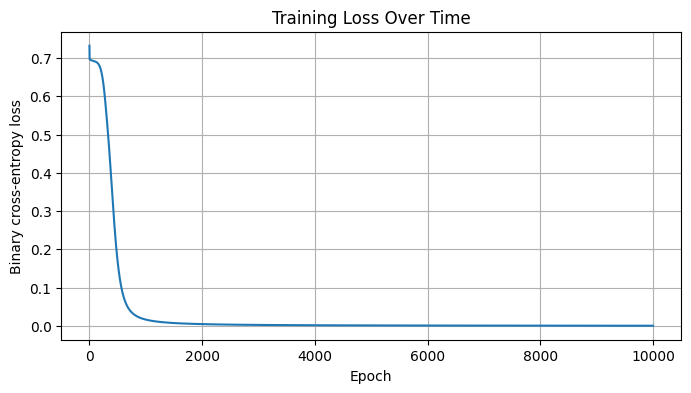

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title('Training Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.grid(True)
plt.show()

## 7. Read the key lines

- `A2 - y` measures the output prediction error for this loss/activation pairing.
- `dW2 = A1.T @ dZ2` calculates how the second layer's weights affect the loss.
- `dA1 @ ...` passes gradient information back toward the hidden layer.
- `W -= learning_rate * dW` updates a parameter in the direction that should reduce loss.

**Remember:** backpropagation calculates gradients; gradient descent (or another optimizer) uses them to update parameters.

## 8. Quick self-check

1. Does backpropagation make the prediction, or calculate gradients from the loss?
2. What does the loss function measure?
3. Which calculus rule helps gradients move backward through multiple layers?

Suggested answers: (1) It calculates gradients. (2) How different predictions are from targets. (3) The chain rule.